# Project 2: Housing Price Prediction – Pass 01

## Problem Definition


State the business problem. Translate the business problem into a Data Science problem by stating what kind of problem it is ( supervised vs unsupervised ) and whether it is a classification, regression, or clustering problem.

Statement:

We want to predict housing sale prices based on various correlated feature data. This is a *supervised regression* problem, where the target of the prediction is sales prices. To accomplish this, we use a regression model alongside Regression prediction techniques, as well as feature scaling and regularization to minimize the RMS percentage error.

## Data Collection/Sources


Data Collection describes the process by which we obtain the data for use in the project. In this case, our data comes from S3 storage buckets on AWS, which we load into memory (variables) via URLs by passing them to the read_csv function of the pandas python library (more on that soon).

The data comes in one large set containing the full data available for use in the project. It is supplemented by a data dictionary that describes the set, the data types of the included data, and other information relevant to its use.

Finally, to store the data in a form we can work with in memory, we use a storage structure called a DataFrame object from the pandas python library. This object allows us to quickly view the data and preview operations on the data without changing it, as well as make updates to the data in a highly intuitive way.

#### Load Pandas, Numpy, and Matplotlib modules

In [ ]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics

Load data Train.csv from AWS S3:

In [ ]:
# url
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'

Next, make a preview DataFrame to look at columns:

In [ ]:
# make preview
df_preview = pd.read_csv(url, nrows=1)
df_preview

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,905101070,20,RL,62.0,14299,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,7,2007,WD,Normal,115400


In [ ]:
# preview all column names
df_preview.columns

Index(['PID', 'MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area', 'Street',
       'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config',
       'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type',
       'House Style', 'Overall Qual', 'Overall Cond', 'Year Built',
       'Year Remod/Add', 'Roof Style', 'Roof Matl', 'Exterior 1st',
       'Exterior 2nd', 'Mas Vnr Type', 'Mas Vnr Area', 'Exter Qual',
       'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure',
       'BsmtFin Type 1', 'BsmtFin SF 1', 'BsmtFin Type 2', 'BsmtFin SF 2',
       'Bsmt Unf SF', 'Total Bsmt SF', 'Heating', 'Heating QC', 'Central Air',
       'Electrical', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF',
       'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath',
       'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'Kitchen Qual',
       'TotRms AbvGrd', 'Functional', 'Fireplaces', 'Fireplace Qu',
       'Garage Type', 'Garage Yr Blt', 'Garage Finish'

Define the target column (and features types, if required):

In [ ]:
# define target column (by name) and features column(s)
target_col = "SalePrice"
feature_cols = ["Lot Frontage"]

Create list of target col and feature cols:

In [ ]:
# use list comprehension to generate list of target col + selected feature cols
selected_cols = [ target_col ] + feature_cols
selected_cols

['SalePrice', 'Lot Frontage']

Read in the data from .csv using target_col and feature_types:

In [ ]:
# make dataframe
df = pd.read_csv( url, usecols=selected_cols )

Finally, check the dataframe:

In [ ]:
# check dataframe
df

,Lot Frontage,SalePrice
0,62.0,115400
1,72.0,90000
2,50.0,141000
3,68.0,254000
4,60.0,155000
...,...,...
2632,52.0,114500
2633,74.0,162000
2634,61.0,211500
2635,78.0,165000


## Data Cleaning


Data Cleaning is the process of preparing the data set for use in analysis. Many data sets contain bad or null (empty) values, which can cause errors when trying to work with the data and use it in code. Cleaning the data involves removing bad (null-containing) columns and/or rows from the set, as well as imputing (replacing via insertion) similar data into fields with missing or unusable values.

Here, to clean the data, we mostly use the pandas drop function included with pandas DataFrame objects, which allow us to drop columns and rows according to conditions we specify, much like SQL WHERE clauses.

#### Examine the data using tools we have used in class. You should be identifying the various columns such as ...

    - target column
    - feature columns
    - identifier columns
    - null columns
    - null rows

    Tools you should be using include, but are not limited to:

    - head
    - tail
    - shape
    - size
    - info
    - describe
    - nunique
    - unique
    - isnull/isna



First, define the target column:

In [ ]:
# check target_col
target_col

'SalePrice'

- head

In [ ]:
# head
df.head()

,Lot Frontage,SalePrice
0,62.0,115400
1,72.0,90000
2,50.0,141000
3,68.0,254000
4,60.0,155000


- tail

In [ ]:
# tail
df.tail()

,Lot Frontage,SalePrice
2632,52.0,114500
2633,74.0,162000
2634,61.0,211500
2635,78.0,165000
2636,41.0,225000


- shape

In [ ]:
# shape
df.shape

(2637, 2)

- size

In [ ]:
# size
df.size

5274

- info

In [ ]:
# info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Lot Frontage  2188 non-null   float64
 1   SalePrice     2637 non-null   int64  
dtypes: float64(1), int64(1)
memory usage: 41.3 KB


- describe

In [ ]:
# describe
df.describe()

,Lot Frontage,SalePrice
count,2188.000000,2637.000000
mean,69.166819,179986.230186
std,23.356779,78309.251522
min,21.000000,12789.000000
25%,58.000000,129500.000000
50%,68.000000,160000.000000
75%,80.000000,213000.000000
max,313.000000,745000.000000


- nunique

In [ ]:
# nunique
df.nunique().sort_values( ascending = False )

,0
SalePrice,983
Lot Frontage,126


In [ ]:
# normalize to look for ID column(s)
df.nunique().sort_values( ascending = False ) / df.shape[0] * 100

,0
SalePrice,37.277209
Lot Frontage,4.778157


- unique

In [ ]:
# unique
df[target_col].unique()

array([115400,  90000, 141000, 254000, 155000, 125000, 194500, 185000,
       235000, 152000, 201000, 207000, 192000, 174000, 190000, 176000,
       384500, 395039, 167000, 165000, 195000, 104500, 161000, 245700,
       226001, 153500, 139000,  35000, 181000, 212000, 156000, 139500,
       225000,  12789, 157500, 110000, 130000, 263000, 205000, 117000,
       200624, 120000, 137900, 245500, 107000, 327000,  93000, 145250,
       168000, 169900, 122000, 161750, 188000, 149500, 421250, 305000,
        50138, 136000, 150750, 307000, 241000,  86900, 202500,  93500,
       121000, 107500, 336000, 213000, 129000, 170000, 337500, 535000,
       173500, 162000,  37900, 158500,  94000, 350000, 140000, 409900,
       115000, 177000,  94750, 121600, 128500, 301000, 230000, 151000,
       137500,  85500, 129400, 191500, 250000, 135000, 119000, 150000,
       178000, 163900, 199000, 203000, 178900, 180000, 182000, 177900,
       122500, 134900, 132000, 147983,  68500, 158000, 260261,  64500,
      

- isnull

In [ ]:
# isnull
df.isnull().sum().sort_values( ascending = False )

,0
Lot Frontage,449
SalePrice,0


In [ ]:
# percent null by column
(df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100

,0
Lot Frontage,17.026925
SalePrice,0.000000


In [ ]:
# look at unique values in the col-by-col null counts to classify cols
((df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100).unique()

array([17.02692454,  0.        ])

In [ ]:
# check to see if anything is not zero -- should return 0 if no nulls
df.isnull().sum().sum()

np.int64(449)

In [ ]:
# how many rows with at least one null
num_rows_with_nulls = df.isna().any(axis=1).sum()
int(num_rows_with_nulls)

449

The target (SalePrice) contains no nulls, but the feature (Lot Frontage) contains about 17% null values. To address this, we can impute values using the median value in that column.

- dtypes

In [ ]:
# dtypes
df.dtypes

,0
Lot Frontage,float64
SalePrice,int64


Examine null columns, columns with some nulls, and columns with no nulls:

In [ ]:
# display columns with all null values
df.isnull().sum()[df.isnull().sum() == df.shape[0]]

,0


In [ ]:
# count these
int(df.isnull().sum()[df.isnull().sum() == df.shape[0]].count())

0

In [ ]:
# show columns with some null values
df.isnull().sum()[(df.isnull().sum() != df.shape[0]) & (df.isnull().sum() != 0)].sort_values( ascending = False )

,0
Lot Frontage,449


In [ ]:
# count these
int(df.isnull().sum()[(df.isnull().sum() != df.shape[0]) & (df.isnull().sum() != 0)].count())

1

In [ ]:
# columns with no nulls
df.isnull().sum()[df.isnull().sum() == 0]

,0
SalePrice,0


In [ ]:
# count these
int(df.isnull().sum()[df.isnull().sum() == 0].count())

1

#### Target: Value Counts

In [ ]:
# value counts on target
df[target_col].value_counts( dropna = False )

,count
SalePrice,
140000,31
135000,30
130000,28
155000,24
160000,22
...,...
160200,1
174190,1
415298,1


In [ ]:
# value counts normalized
df[target_col].value_counts( dropna = False, normalize = True ) * 100

,proportion
SalePrice,
140000,1.175578
135000,1.137656
130000,1.061813
155000,0.910125
160000,0.834281
...,...
160200,0.037922
174190,0.037922
415298,0.037922


In [ ]:
# target col size/shape
df[[target_col]].shape[0]

2637

In [ ]:
# sum of nulls in target
int(df[[target_col]].isnull().sum().iloc[0])

0

In [ ]:
# sum of non-nulls in target
df[[target_col]].shape[0] - int(df[[target_col]].isnull().sum().iloc[0])

2637

There are no nulls in the target column, which means no rows will need to be dropped on its account.

#### Summary:

This abridged dataset contains 2637 rows and 2 columns, making for a total of 5274 entries of data. Many of these fields are null.

Details:

  - target column: 'SalePrice'
  - feature columns: ['Lot Frontage']
  - identifier columns: n/a
  - null columns: 0
  - null rows (target): 0
  - null rows (any): 449 / 2637 (~17%)

#### If there are data cleaning issues, develop recommendations for how to deal with them.  Specifically, handle these common issues:

    - identifer columns
    - target column with null counts
    - feature columns with high null counts
    - feature columns with low null counts
    - feature columns with medium null counts


In [ ]:
# head again to double-check
df.head()

,Lot Frontage,SalePrice
0,62.0,115400
1,72.0,90000
2,50.0,141000
3,68.0,254000
4,60.0,155000


In [ ]:
# make backup
df_bak = df.copy()
df_bak

,Lot Frontage,SalePrice
0,62.0,115400
1,72.0,90000
2,50.0,141000
3,68.0,254000
4,60.0,155000
...,...,...
2632,52.0,114500
2633,74.0,162000
2634,61.0,211500
2635,78.0,165000


In [ ]:
# restore from backup
df = df_bak.copy()
df

,Lot Frontage,SalePrice
0,62.0,115400
1,72.0,90000
2,50.0,141000
3,68.0,254000
4,60.0,155000
...,...,...
2632,52.0,114500
2633,74.0,162000
2634,61.0,211500
2635,78.0,165000


1. Remove identifier columns

- No identifier rows present in set (culled at read level)

2. Drop null target rows



- No null target rows

3. Drop feature columns with many or all nulls

- No null feature columns

4. Drop remaining records with null counts (if few)

- null % in feature above 5-10%, so we avoid dropping rows

5.  Impute with the median for remaining fields

In [ ]:
# check again how many of each column is null
df.isnull().sum().sort_values( ascending = False )

,0
Lot Frontage,449
SalePrice,0


In [ ]:
# normalize null counts (per column)
df.isnull().sum().sort_values( ascending = False ) / df.shape[0] * 100

,0
Lot Frontage,17.026925
SalePrice,0.000000


Impute:

In [ ]:
feature_cols = list(df.drop(columns = target_col).columns)
feature_cols

['Lot Frontage']

In [ ]:
# loop through features to bulk impute with respective column medians
for feature_col in feature_cols:

  # Calculate the median
  median = df[feature_col].median()
  print(median)

  # Assign median to nulls
  df.fillna( {feature_col: median}, inplace = True )

  # Verify median is about the same as before
  print(df[feature_col].median())

68.0
68.0


In [ ]:
df

,Lot Frontage,SalePrice
0,62.0,115400
1,72.0,90000
2,50.0,141000
3,68.0,254000
4,60.0,155000
...,...,...
2632,52.0,114500
2633,74.0,162000
2634,61.0,211500
2635,78.0,165000


In [ ]:
# check again how many of each column is null
df.isnull().sum().sort_values( ascending = False )

,0
Lot Frontage,0
SalePrice,0


In [ ]:
# backup 2
df_bak2 = df.copy()

In [ ]:
# restore from backup 2
df = df_bak2.copy()

In [ ]:
df

,Lot Frontage,SalePrice
0,62.0,115400
1,72.0,90000
2,50.0,141000
3,68.0,254000
4,60.0,155000
...,...,...
2632,52.0,114500
2633,74.0,162000
2634,61.0,211500
2635,78.0,165000


In [ ]:
# check total null counts sum
f"Number of remaining nulls in df: {int(df.isnull().sum().sum())}"

'Number of remaining nulls in df: 0'

## Exploratory Data Analysis


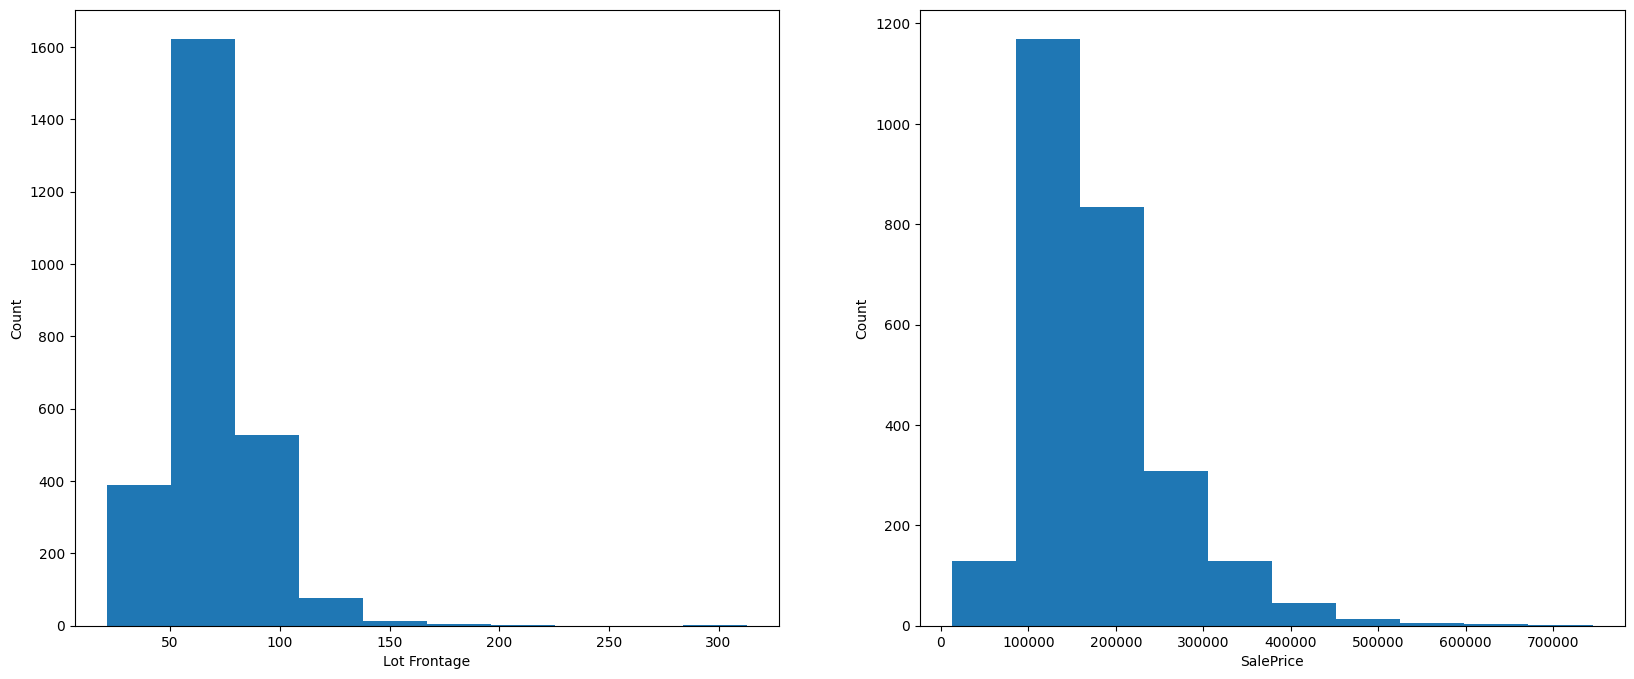

In [ ]:
# Let's plot mpg and all of our predictors
fig, subplot = plt.subplots(1,2, figsize = (20,8)) # Creating 2x4 subplots because we have 8 columns in our data
column_names = df.columns
n = 0
for i in range(2): # Loop through rows
  # for j in range(2): # Loop through columns
    subplot[i].hist(df[column_names[n]])
    subplot[i].set_xlabel(column_names[n])
    subplot[i].set_ylabel('Count')
    n = n + 1

### What do we notice?

- SalePrice and Lot Frontage are positively skewed
- Perhaps some outliers

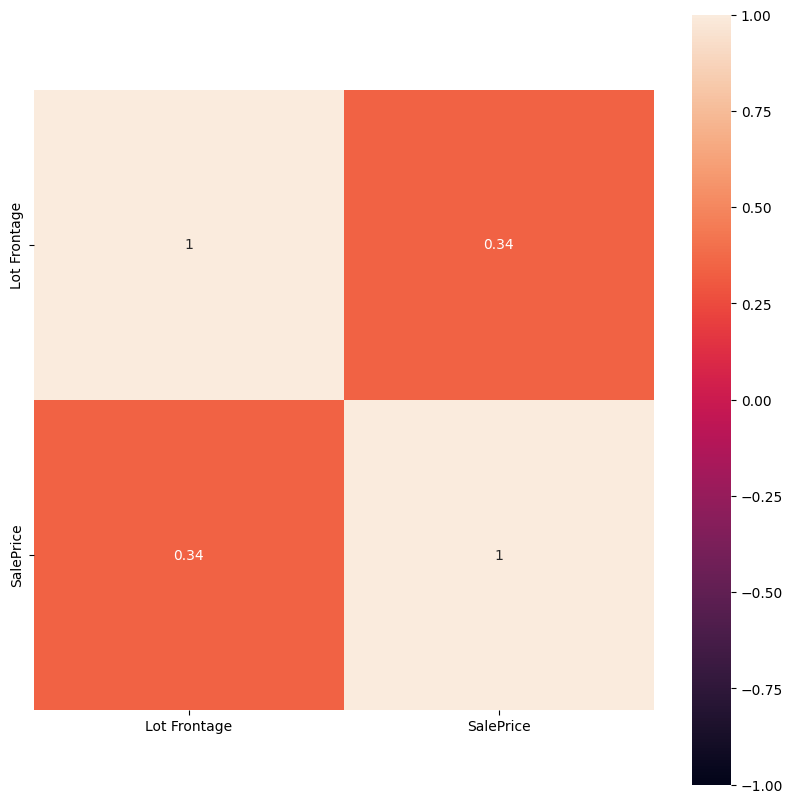

In [ ]:
# Let's take a look at a correlation plot
plt.figure(figsize=(10,10))
correlation_matrix = df.corr().round(2)
sns.heatmap(data=correlation_matrix, annot=True, vmin=-1, vmax=1, square=True) ;



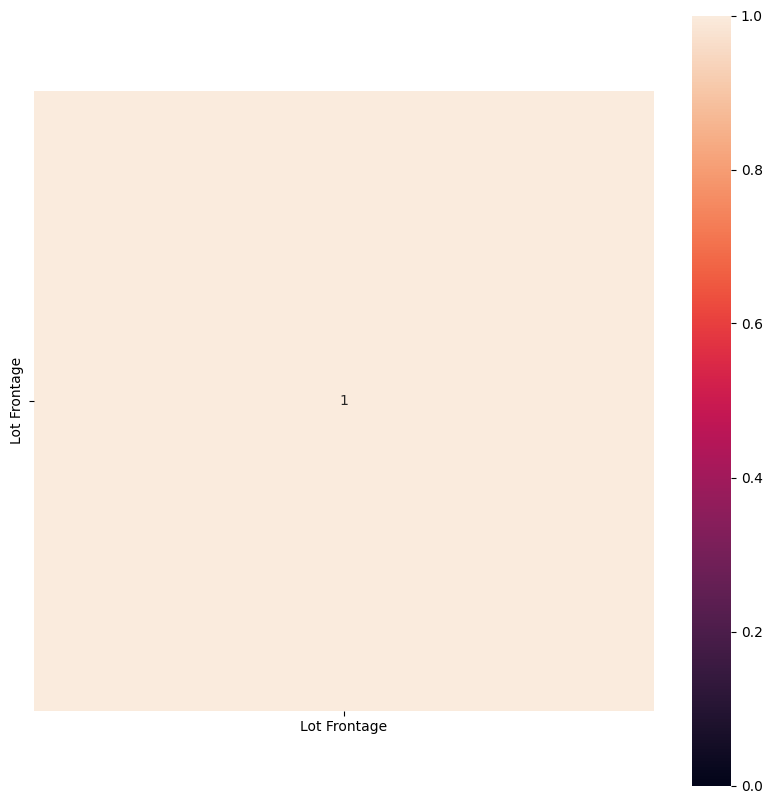

In [ ]:
# Let's take a look at a correlation plot
plt.figure(figsize=(10,10))
correlation_matrix = df.drop( columns = [target_col] ).corr().abs().round(2)
sns.heatmap(data=correlation_matrix, annot=True, vmin=0, vmax=1, square=True) ;



In [ ]:
correlation_matrix = df.corr().round(2)
correlation_matrix[target_col].abs().sort_values(ascending=False)

,SalePrice
SalePrice,1.00
Lot Frontage,0.34


<Axes: >

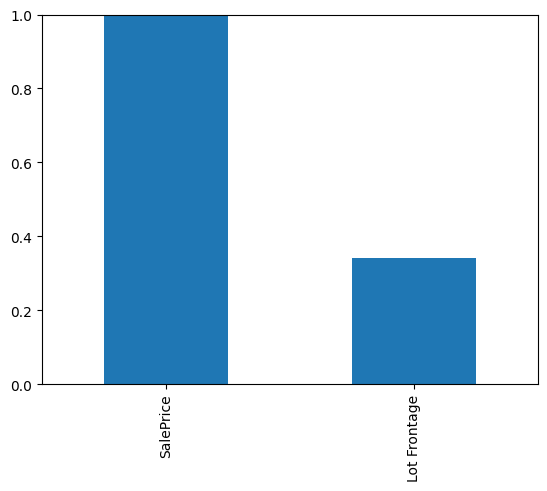

In [ ]:
correlation_matrix = df.corr().round(2)
correlation_matrix[target_col].abs().sort_values(ascending=False).plot( kind="bar", ylim = [0,1])

In [ ]:
corrs = df.corr().round(2).unstack().abs()
corrs.reset_index()

,level_0,level_1,0
0,Lot Frontage,Lot Frontage,1.00
1,Lot Frontage,SalePrice,0.34
2,SalePrice,Lot Frontage,0.34
3,SalePrice,SalePrice,1.00


In [ ]:
corrs = corrs[corrs < 1]
corrs.reset_index()

,level_0,level_1,0
0,Lot Frontage,SalePrice,0.34
1,SalePrice,Lot Frontage,0.34


In [ ]:
corrs.sort_values(ascending = False).reset_index()

,level_0,level_1,0
0,Lot Frontage,SalePrice,0.34
1,SalePrice,Lot Frontage,0.34


In [ ]:
corrs.sort_values(ascending = False)[::2].reset_index()

,level_0,level_1,0
0,Lot Frontage,SalePrice,0.34


### What do we notice?

- SalePrice vs. Lot Frontage do not appear to be highly correlated to each other

In [ ]:
df.size

5274

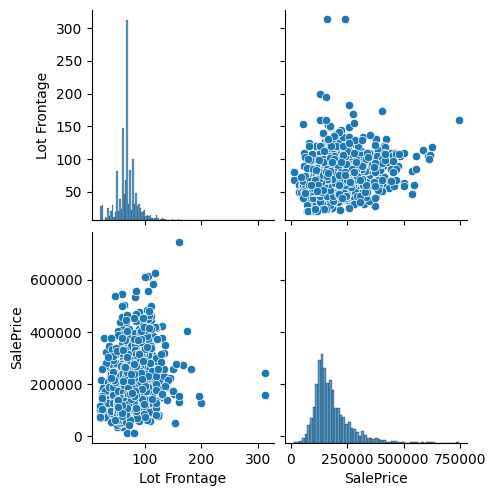

In [ ]:
# Let's plot a pairplot
sns.pairplot(df) ;



### What do we notice?

- SalePrice vs. Lot Frontage is rather scattered, and does not appear to be linear.

## Processing



## Data Visualization/Communication of Results
